<a href="https://colab.research.google.com/github/SonalJC/Brain-Tumor-MRI-Image-Classification/blob/main/Flipkart_Customer_Satisfaction_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Project Name**    - Flipkart Customer Satisfaction Analysis



##### **Project Type**    - EDA-Exploratory Data Analysis
##### **Contribution**    - Individual


# **Project Summary -**

The project "Flipkart Customer Service Satisfaction Analysis" focuses on analyzing customer support data to understand what factors affect customer satisfaction. The goal is to find patterns that can help improve the overall support experience for customers.

The dataset includes details such as agent name , agent shifts, product categories, response time, and CSAT (Customer Satisfaction) scores etc.

The first step in the project was data cleaning, where missing values were handled, and irrelevant columns were removed. After that, feature engineering was done by creating new columns like response_time to get more useful insights.

Then, Exploratory Data Analysis (EDA) was performed using univariate, bivariate, and multivariate analysis. bar plots, line charts, histograms and heatmaps were used to visualize the data and understand relationships between different variables.

It was found that factors like quick response time, type of support channel, and agent's working shift were associated with clear differences in customer satisfaction.

It was found that response time, support channel, product category and manager were associated with clear differences in customer satisfaction

# **Problem Statement**


Flipkart gets many customer complaints every day through chat, call, or email. To keep customers happy, it is important to understand what makes them feel satisfied with the service.

This project studies customer support data to find out which factors (like response time, support channel, agent details, etc.) affect customer satisfaction. A machine learning model is also used to predict if a customer will be satisfied or not, based on these factors. This helps in improving customer service using data.

#### **Define Your Business Objective?**

The main objective is to understand what affects customer satisfaction in Flipkart’s customer service and find ways to improve service quality using the support data

# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [330]:
# Import Libraries
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Dataset Loading

In [331]:
#mount Collab with google drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [332]:
#load dataset

path='/content/drive/MyDrive/Colab Notebooks/Customer_support_data.csv'
# Load data
df = pd.read_csv(path)
#(pd.read_csv('Customer_support_data.csv'))


### Dataset First View

In [333]:
# Dataset First Look

df.sample(4)

,Unique id,channel_name,category,Sub-category,Customer Remarks,Order_id,order_date_time,Issue_reported at,issue_responded,Survey_response_Date,Customer_City,Product_category,Item_price,connected_handling_time,Agent_name,Supervisor,Manager,Tenure Bucket,Agent Shift,CSAT Score
68793,b5ec61ea-771c-4a18-8ebe-8b0f7ad85315,Inbound,Returns,Damaged,NaN,35cf14fe-1a30-4828-b771-05ec3cf4a9be,NaN,25/08/2023 15:24,26/08/2023 17:22,26-Aug-23,NaN,NaN,NaN,NaN,Alyssa Ford,Carter Park,Jennifer Nguyen,On Job Training,Morning,5
76269,7295dad7-b2ae-464d-bbfc-e208e40d9dae,Email,Returns,Fraudulent User,NaN,62465746-5500-4aa7-b419-17879da98083,NaN,28/08/2023 13:03,28/08/2023 00:00,28-Aug-23,NaN,NaN,NaN,NaN,John Gonzalez,Noah Patel,Michael Lee,31-60,Night,4
73054,eb85a8a2-8fe9-4dcd-9812-4fb977864049,Inbound,Feedback,UnProfessional Behaviour,NaN,NaN,NaN,27/08/2023 10:02,27/08/2023 10:07,27-Aug-23,NaN,NaN,NaN,NaN,Sarah Henderson,Ava Wong,Jennifer Nguyen,On Job Training,Morning,5
30020,579541f8-794c-44e3-a399-c6243a70a6ef,Email,Order Related,Delayed,NaN,NaN,NaN,12/08/2023 21:16,12/08/2023 21:22,12-Aug-23,NaN,NaN,NaN,NaN,Carla Burke,Amelia Tanaka,Michael Lee,31-60,Evening,5


### Dataset Rows & Columns count

In [334]:
# Dataset Rows & Columns count
rows,columns=df.shape
print("Number of rows:",rows)
print("Number of columns:",columns)


Number of rows: 85907
Number of columns: 20


### Dataset Information

In [335]:
# Dataset Info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85907 entries, 0 to 85906
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Unique id                85907 non-null  object 
 1   channel_name             85907 non-null  object 
 2   category                 85907 non-null  object 
 3   Sub-category             85907 non-null  object 
 4   Customer Remarks         28742 non-null  object 
 5   Order_id                 67675 non-null  object 
 6   order_date_time          17214 non-null  object 
 7   Issue_reported at        85907 non-null  object 
 8   issue_responded          85907 non-null  object 
 9   Survey_response_Date     85907 non-null  object 
 10  Customer_City            17079 non-null  object 
 11  Product_category         17196 non-null  object 
 12  Item_price               17206 non-null  float64
 13  connected_handling_time  242 non-null    float64
 14  Agent_name            

Unique_id – Unique ID given to each customer or record.

channel_name – How the customer contacted support.
category – Main category related to the customer issue.

Sub-category – Sub-category within the main category.
Customer Remarks – Comments or feedback given by the customer.

Order_id – ID of the order related to the issue.

order_date_time – Date and time of the order placed.

Issue_reported at – When the issue was reported.
issue_responded –

 When the support team responded to the issue.
Survey_response_Date –

 Date the customer filled the survey.

Customer_City – City of the customer.

Product_category –
 Product type involved in the complaint.

Item_price – Price of the item ordered.

connected_handling_time – Time taken by the agent to handle the case.

Agent_name – Name of the support agent.

Supervisor – Name of the agent’s supervisor.

Manager – Name of the manager.

Tenure Bucket – Agent’s experience range.

Agent Shift – Agent’s working shift (day or night).

CSAT Score – Customer satisfaction score (1 to 5).

###Describe unique values

In [336]:
df.nunique()

,0
Unique id,85907
channel_name,3
category,12
Sub-category,57
Customer Remarks,18231
Order_id,67675
order_date_time,13766
Issue_reported at,30923
issue_responded,30262
Survey_response_Date,31


### Check Missing values and handle  them

In [337]:
df.isna().mean()*100

,0
Unique id,0.000000
channel_name,0.000000
category,0.000000
Sub-category,0.000000
Customer Remarks,66.542889
Order_id,21.222950
order_date_time,79.962052
Issue_reported at,0.000000
issue_responded,0.000000
Survey_response_Date,0.000000


In [338]:
# Drop columns with too many missing values

 # it is identifer not useful for finding target column
df=df.drop(columns=['Unique id'])

#used the part of the feature which is not missing. and drop the Order_id.
df['has_order_info']=df['Order_id'].notna().astype(int)
df=df.drop(columns=['Order_id'])

#large data are missing and it is not useful for target column.
df = df.drop(columns=['connected_handling_time'])  # too sparse

#used the avilable part of the data and remove raw column.
df['has_city_info']=df['Customer_City'].notna().astype(int)
df=df.drop(columns=['Customer_City'])

# 90% data are missing so drop it
df=df.drop(columns=['order_date_time'])

# Unknown or missing remarks fill with labels.
df['Customer Remarks']=df['Customer Remarks'].fillna("No Remarks")
df['Product_category']=df['Product_category'].fillna("Unknown")
df['Price_known']=df['Item_price'].notna()
df=df.drop(columns=['Item_price'])

### Duplicate Columns

In [339]:
df.duplicated().sum()

np.int64(9)

9 duplicate rows (0.01%) kept, negligible.

### DateTime Formating

In [340]:
df['Survey_response_Date'] = pd.to_datetime(df['Survey_response_Date'], format='%d-%b-%y',errors='coerce')
df['Issue_reported at']=pd.to_datetime(df['Issue_reported at'],format='%d/%m/%Y %H:%M',errors='coerce')
df['issue_responded']=pd.to_datetime(df['issue_responded'],format='%d/%m/%Y %H:%M',errors='coerce')


In [341]:
#rename the column name
df=df.rename(columns={'Issue_reported at':'Issue_reported_at'})
#find the timedelta
df['response_time']=df['issue_responded']-df['Issue_reported_at']
df['response_time']=df['response_time'].dt.total_seconds()/60

# Handline Negative values in response_time columns
(df['response_time'] < 0).sum()
df.loc[df['response_time']<0,'response_time']=np.nan

### Target variable - % Distribution

In [342]:
df['CSAT Score'].value_counts(normalize=True)*100

,proportion
CSAT Score,
5,69.397139
1,13.072276
4,13.059471
3,2.977639
2,1.493476


Convert target variable into Satisfied label- (0 and 1)

In [343]:
df['Satisfied']=df['CSAT Score']

In [344]:
# divide the it into binary classification 0 for not satisfied and 1 satisfied
df['Satisfied']=df['CSAT Score'].apply(lambda x:1 if x>=4 else 0)

In [345]:
df['Satisfied'].value_counts(normalize=True)*100

,proportion
Satisfied,
1,82.45661
0,17.54339


### Response Time Buckets

In [346]:
# it divides time into different category.
df['response_bucket']=pd.cut(df['response_time'],
             bins=[-0.01,2,5,15,60,240,np.inf],
             labels=['<=2 min','2-5 min','5-15 min','15-60 min','1-4 hr','>4 hr'])
print(df['response_bucket'])

0        15-60 min
1          <=2 min
2        15-60 min
3        15-60 min
4          <=2 min
           ...    
85902        >4 hr
85903      <=2 min
85904      2-5 min
85905      <=2 min
85906      <=2 min
Name: response_bucket, Length: 85907, dtype: category
Categories (6, object): ['<=2 min' < '2-5 min' < '5-15 min' < '15-60 min' < '1-4 hr' < '>4 hr']


In [347]:
#response bucket 6 categories
df['response_bucket'].value_counts(normalize=True).sort_index().round(3)*100

,proportion
response_bucket,
<=2 min,28.7
2-5 min,20.2
5-15 min,16.8
15-60 min,12.5
1-4 hr,8.9
>4 hr,12.9


In [348]:
#time taken by 90th and 99th quantile
df['response_time'].quantile([.9, .99])

,response_time
0.90,432.00
0.99,3047.22


### Weekday and time based Report

In [349]:
#
df['report_hour']=df['Issue_reported_at'].dt.hour
df['dayofweek']=df['Issue_reported_at'].dt.dayofweek
# report_hour is slightly higher in early morning and night and lower in(84%-86%) but lower in busy day time (80%-81%).
print(df.groupby(df['report_hour'])['CSAT Score'].agg(['mean','size']))
df.groupby(df['dayofweek'])['CSAT Score'].agg(['mean','size'])


                 mean  size
report_hour                
0            4.319737  1520
1            4.212560   414
2            4.207143   140
3            4.460674    89
4            4.040541    74
5            4.157576   165
6            4.294181   928
7            4.353156  2186
8            4.296381  3482
9            4.217002  4470
10           4.173287  5488
11           4.183373  5906
12           4.206585  5862
13           4.202210  5430
14           4.221107  5382
15           4.274861  4686
16           4.243311  5606
17           4.234351  5927
18           4.216609  5780
19           4.234014  5880
20           4.256256  5635
21           4.279942  4826
22           4.328103  3633
23           4.372811  2398


,mean,size
dayofweek,,
0,4.228989,12053
1,4.239182,14282
2,4.226583,13633
3,4.253496,13803
4,4.229080,10564
5,4.255786,10630
6,4.265034,10942


###Missing Data Heatmap

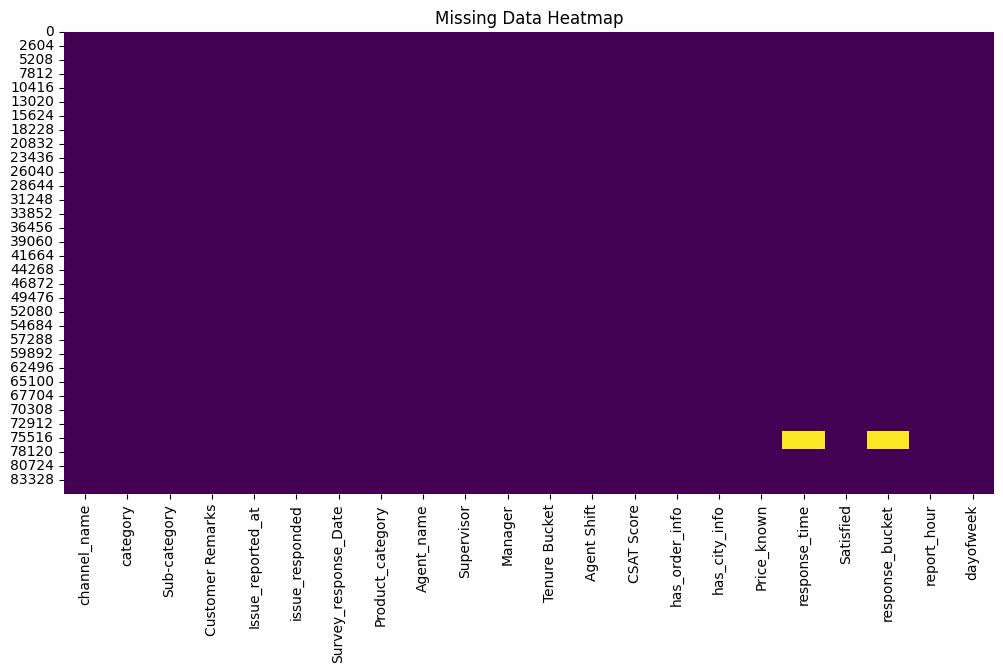

In [350]:
# Visualizing the missing values
plt.figure(figsize=(12, 6))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title("Missing Data Heatmap")
plt.show()

In [351]:
#In above Heatmap chart yellow color show the missing data in specific columns.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

### It Shows the Customer Satisfaction Score by Channel name

Chart 1: CSAT Score vs Channel Name

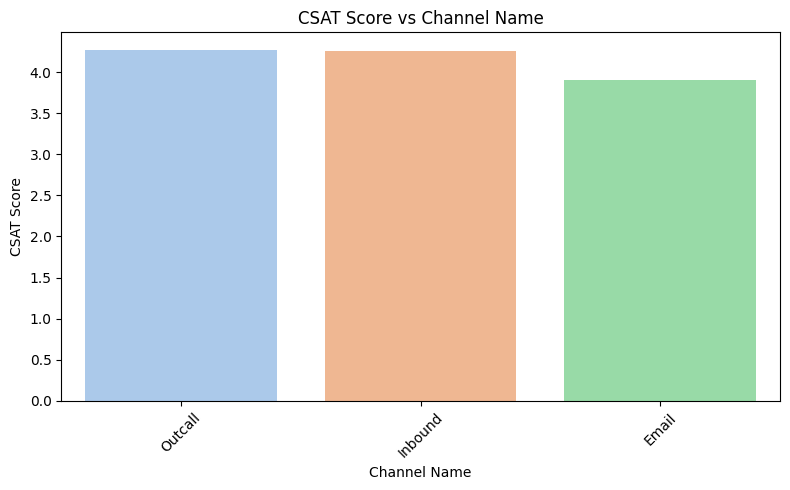

In [352]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=df,
    x='channel_name',
    y='CSAT Score',
    palette='pastel',
    errorbar=None
)

plt.title("CSAT Score vs Channel Name")
plt.xlabel("Channel Name")
plt.ylabel("CSAT Score")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

1. What insights we found in above chart?


Email having lowest CSAT Score between 4-5 and Outcall and Inbound CSAT Score More than 4.

Chart 2: CSAT Score vs Category

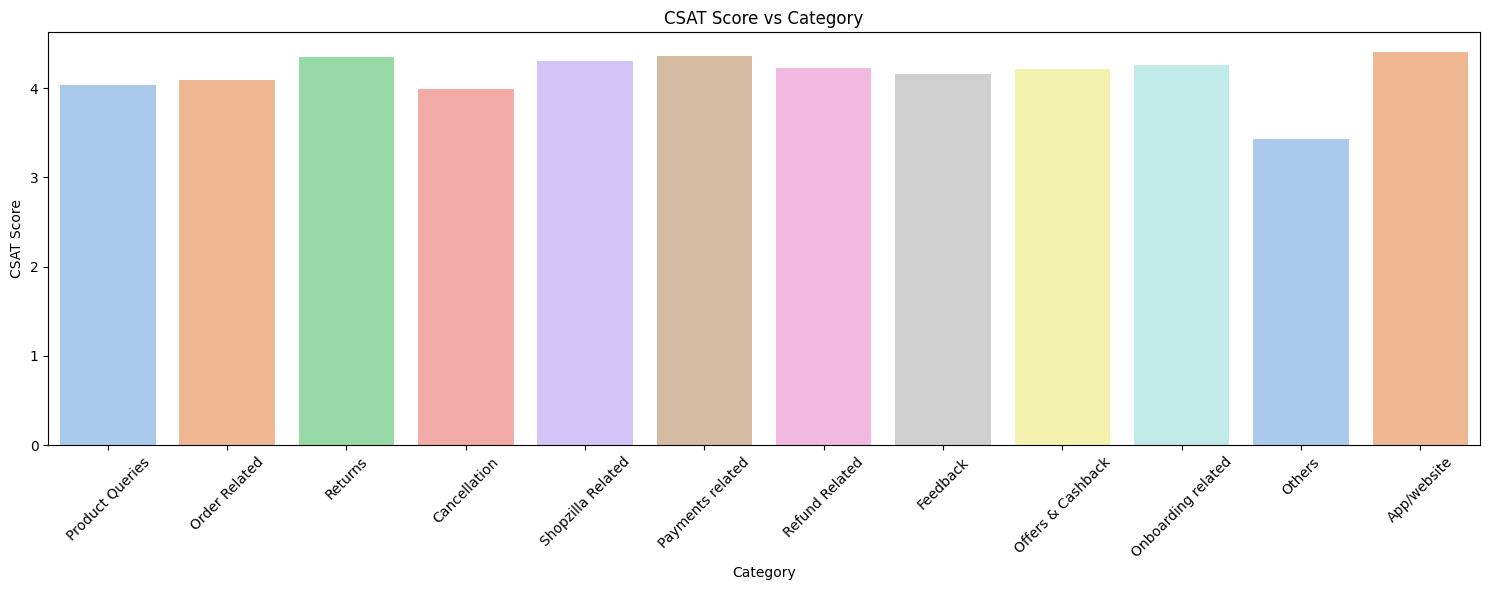

In [353]:
plt.figure(figsize=(15,6))

sns.barplot(
    data=df,
    x='category',
    y='CSAT Score',
    palette='pastel',
    errorbar=None
)

plt.title("CSAT Score vs Category")
plt.xlabel("Category")
plt.ylabel("CSAT Score")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

Chart- 1 Univariate analysis for Numerical Column(CSAT Score).

Share of responses by score (%):
CSAT Score
1    13.1
2     1.5
3     3.0
4    13.1
5    69.4

Satisfied (4-5): 82.5%  |  Unsatisfied (1-3): 17.5%


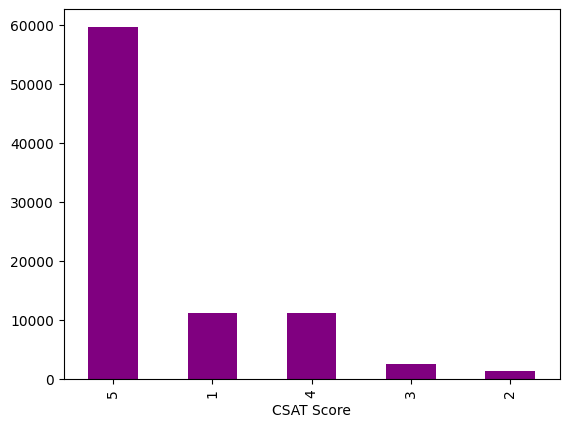

In [354]:
#analyze  Numerical column (Satisfied) analysis
df['CSAT Score'].value_counts().plot(kind='bar',color='purple')

dist = (df["CSAT Score"].value_counts(normalize=True).sort_index() * 100).round(1)
print("Share of responses by score (%):")
print(dist.to_string())
df['Satisfied']=df['Satisfied'].astype(int)
print(f"\nSatisfied (4-5): {df['Satisfied'].mean()*100:.1f}%  |  Unsatisfied (1-3): {(1-df['Satisfied'].mean())*100:.1f}%")

In [355]:
# This bar chart shows how often each Satisfaction occurs in the data.
# Higher side, indicating good satisfaction.


 1. Why did you pick the specific chart?

 Here we use count plot to count the number of CSAT Score.

2. What is/are the insight(s) found from the chart?

    Using CSAT Scroe we can analysis how many customers are satisfied according to the rating.

Chart - 2 Complaint By Product Category (Count Plot)

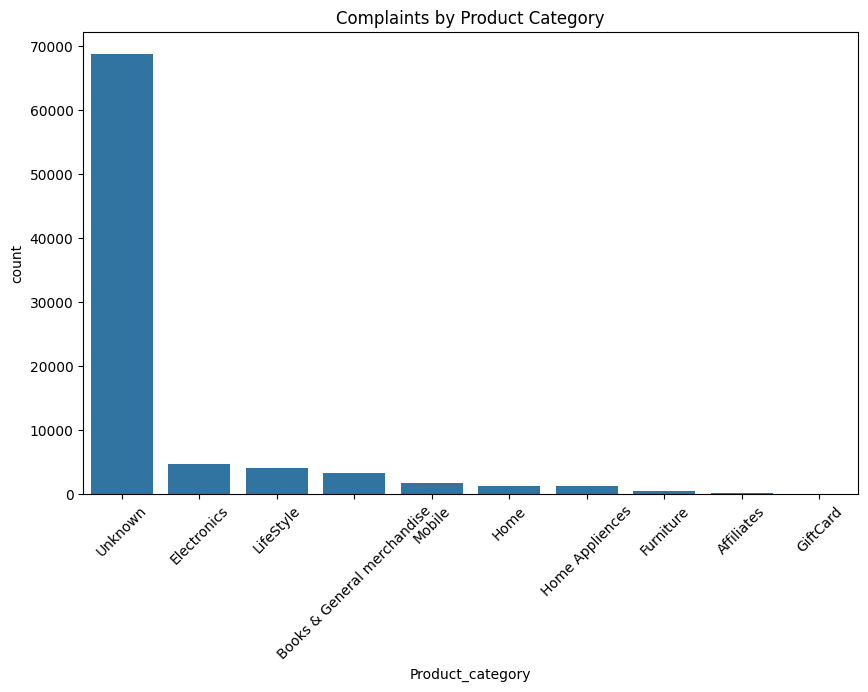

Share of Complaints by Product Category %
Product_category
Unknown                        80.0
Electronics                     5.5
LifeStyle                       4.8
Books & General merchandise     3.9
Mobile                          2.0
Home                            1.5
Home Appliences                 1.5
Furniture                       0.5
Affiliates                      0.2
GiftCard                        0.0


In [356]:
# Chart - 2 visualization code

plt.figure(figsize=(10,6))
sns.countplot(data=df, x='Product_category', order=df['Product_category'].value_counts().index)
plt.xticks(rotation=45)
plt.title('Complaints by Product Category')
plt.show()

dist=(df['Product_category'].value_counts(normalize=True)*100).round(1)
print("Share of Complaints by Product Category %")
print(dist.to_string())


In [357]:
# This count plot shows the number of complaints for each product category.
# It helps identify which categories have the most customer issues.
# This insight can guide where to improve product quality or service.


##### 1. Why did you pick the specific chart?

Here we use Bar Chart to compare categories like product types, shifts, or cities.
It helps us see which category has more issues/complaints or more support requests.

##### 2. What is/are the insight(s) found from the chart?

We use a bar chart to visualize product categories because it effectively displays the number of complaints and issues related to each category. This helps us quickly identify which product categories have the highest customer dissatisfaction or frequent problems, allowing us to focus on improving those areas. The bar chart provides a clear, straightforward comparison between categories, making it easy to spot trends and prioritize actions.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.


Note:A large number of rows in the dataset have the product category listed as "unknown". These entries do not mention the specific type of product related to the support issue.They form mj=ajor parts of the data so we keep it for data analysis.

### Response Time

#### Chart - 3 (Pie Chart)

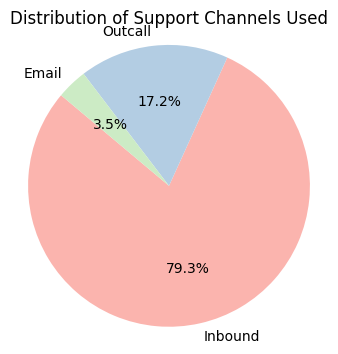

In [358]:
# Chart - 2 visualization code

# Count the values in channel_name
channel_counts = df['channel_name'].value_counts()

# Create pie chart
plt.figure(figsize=(4,4))
plt.pie(channel_counts, labels=channel_counts.index, autopct='%1.1f%%', startangle=140, colors=plt.cm.Pastel1.colors)
plt.title('Distribution of Support Channels Used')
plt.axis('equal')  # Keeps pie chart circular
plt.show()


In [359]:
# This pie chart shows the percentage of customer issues handled by each support channel.
# It helps us see which channels are most commonly used by customers.
# Knowing this can help focus resources on the busiest channels.


##### 1. Why did you pick the specific chart?

This pie chart displays the percentage usage of different support channels (like WhatsApp, Phone Call, Email) that customers used to raise their issues.



##### 2. What is/are the insight(s) found from the chart?

Most of the support interactions are inbound, meaning customers are contacting the company first. This shows that many issues are not solved automatically, and customers have to reach out for help.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

If too many inbound requests are coming, it may mean the company is not being active in solving problems. This can lead to lower customer satisfaction.


#### Chart - 4 (Count Plot)

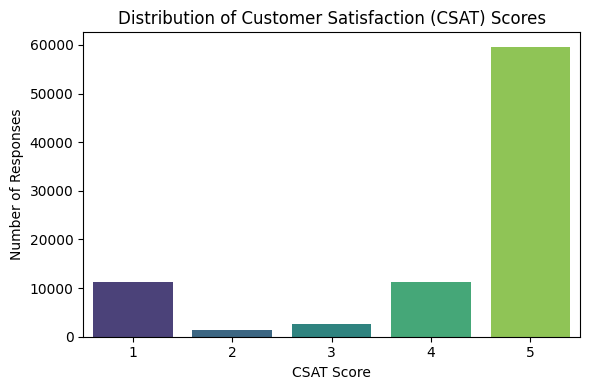

In [360]:
# Chart - 3 visualization code
# Plot count of each CSAT score
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='CSAT Score', palette='viridis')
plt.title('Distribution of Customer Satisfaction (CSAT) Scores')
plt.xlabel('CSAT Score')
plt.ylabel('Number of Responses')
plt.tight_layout()
plt.show()

In [361]:
# This count plot shows how many customers gave each CSAT score.
# It helps us understand the overall customer satisfaction distribution.
# Most customers seem to give higher scores, indicating good satisfaction.


##### 1. Why did you pick the specific chart?

We used a bar chart because it helps to clearly compare the count of each Satisfied score. It shows how many customers gave a rating from 1 to 5.

##### 2. What is/are the insight(s) found from the chart?

Most customers gave a Satisfied score of 4 and 5, which means many customers are happy.

Few customers gave 1 or 2, showing some dissatisfaction still exists.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, by knowing that most ratings are high, Flipkart can continue the strategies that are working well.
Also, understanding low ratings can help fix weak points and improve customer experience.

### Chart - Satisfied % of Product Category

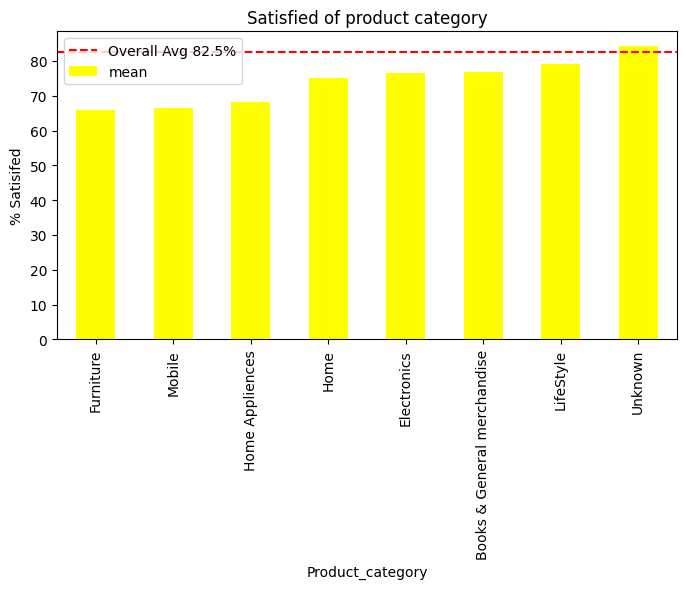

                                  mean   size
Product_category                             
Furniture                    66.029724    471
Mobile                       66.552901   1758
Home Appliences              68.307692   1300
Home                         75.150602   1328
Electronics                  76.540586   4706
Books & General merchandise  76.737887   3323
LifeStyle                    79.164643   4118
Unknown                      84.273260  68711


In [362]:
df['Satisfied']=df['Satisfied'].astype(int)
avg=df['Satisfied'].mean()*100
g=df.groupby('Product_category')['Satisfied'].agg(['mean','size'])
g['mean']=g['mean']*100
g=g[g['size']>=200].sort_values('mean')
g['mean'].plot(kind='bar',color='yellow',figsize=(8,4))

plt.axhline(avg,color='red',linestyle='--',label=f"Overall Avg {avg:.1f}%")
plt.title("Satisfied of product category")
plt.ylabel('% Satisifed')
plt.legend()
plt.show()
print(g)

###Chart - Satisfied % of Agent Shift

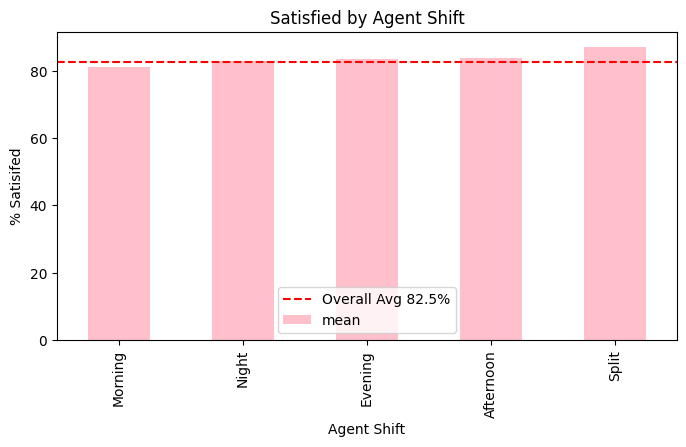

                  mean   size
Agent Shift                  
Morning      81.130208  41426
Night        82.826748   1316
Evening      83.338777  33677
Afternoon    83.767123   5840
Split        87.143640   3648


In [363]:
df['Satisfied']=df['Satisfied'].astype(int)
avg=df['Satisfied'].mean()*100
g=df.groupby('Agent Shift')['Satisfied'].agg(['mean','size'])
g['mean']=g['mean']*100
g=g[g['size']>=200].sort_values('mean')
g['mean'].plot(kind='bar',color='pink',figsize=(8,4))

plt.axhline(avg,color='red',linestyle='--',label=f"Overall Avg {avg:.1f}%")
plt.title("Satisfied by Agent Shift")
plt.ylabel('% Satisifed')
plt.legend()
plt.show()
print(g)

Satisfied by Manager

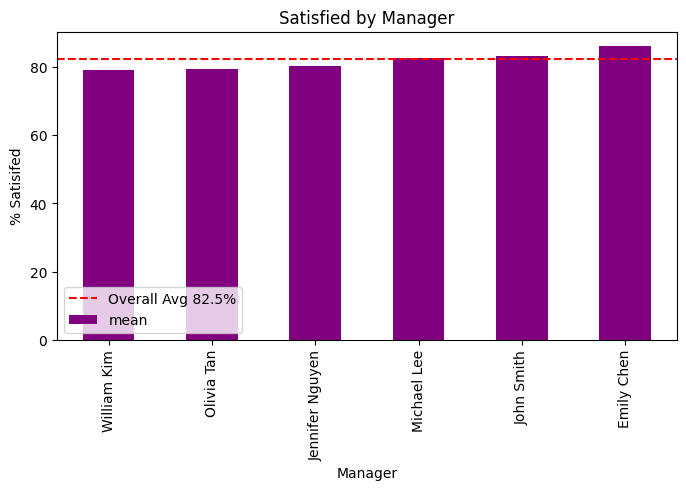

                      mean   size
Manager                          
William Kim      79.260037   8568
Olivia Tan       79.442355   4519
Jennifer Nguyen  80.417689  15897
Michael Lee      82.755682  17600
John Smith       83.143977  25261
Emily Chen       86.068838  14062


In [364]:
df['Satisfied']=df['Satisfied'].astype(int)
avg=df['Satisfied'].mean()*100
g=df.groupby('Manager')['Satisfied'].agg(['mean','size'])
g['mean']=g['mean']*100
g=g[g['size']>=200].sort_values('mean')
g['mean'].plot(kind='bar',color='purple',figsize=(8,4))

plt.axhline(avg,color='red',linestyle='--',label=f"Overall Avg {avg:.1f}%")
plt.title("Satisfied by Manager")
plt.ylabel('% Satisifed')
plt.legend()
plt.show()
print(g)

### Satisfied by Channel Name

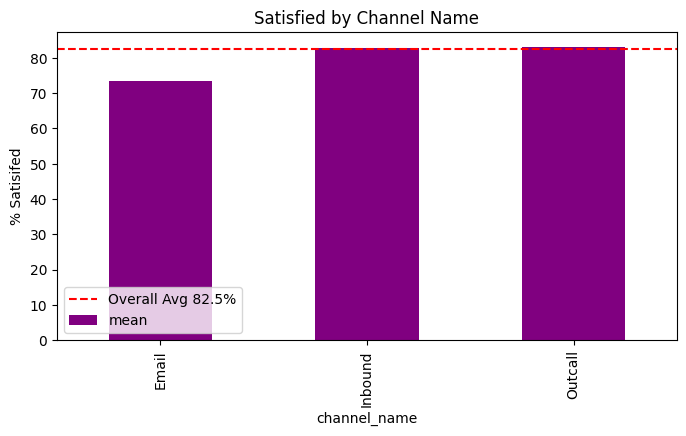

                   mean   size
channel_name                  
Email         73.470063   3023
Inbound       82.699363  68142
Outcall       83.177317  14742


In [365]:
df['Satisfied']=df['Satisfied'].astype(int)
avg=df['Satisfied'].mean()*100
g=df.groupby('channel_name')['Satisfied'].agg(['mean','size'])
g['mean']=g['mean']*100
g=g[g['size']>=200].sort_values('mean')
g['mean'].plot(kind='bar',color='purple',figsize=(8,4))

plt.axhline(avg,color='red',linestyle='--',label=f"Overall Avg {avg:.1f}%")
plt.title("Satisfied by Channel Name")
plt.ylabel('% Satisifed')
plt.legend()
plt.show()
print(g)

### Satisfied by Category

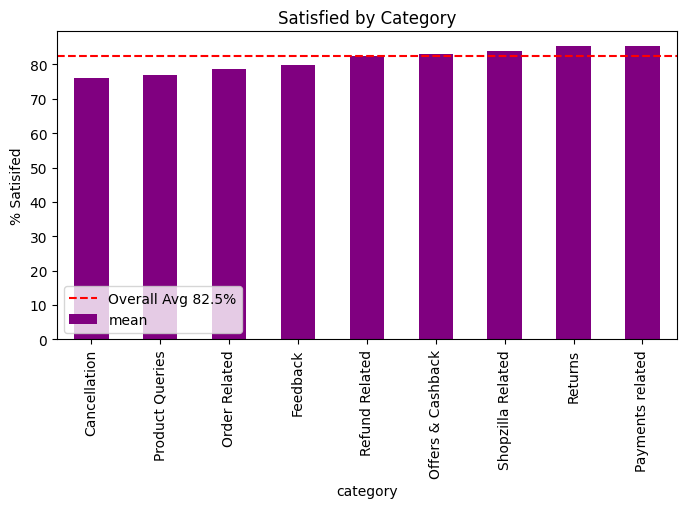

                        mean   size
category                           
Cancellation       75.904159   2212
Product Queries    76.895991   3692
Order Related      78.556967  23215
Feedback           79.860506   2294
Refund Related     82.329670   4550
Offers & Cashback  82.916667    480
Shopzilla Related  83.989971   2792
Returns            85.243894  44097
Payments related   85.302965   2327


In [366]:
df['Satisfied']=df['Satisfied'].astype(int)
avg=df['Satisfied'].mean()*100
g=df.groupby('category')['Satisfied'].agg(['mean','size'])
g['mean']=g['mean']*100
g=g[g['size']>=200].sort_values('mean')
g['mean'].plot(kind='bar',color='purple',figsize=(8,4))

plt.axhline(avg,color='red',linestyle='--',label=f"Overall Avg {avg:.1f}%")
plt.title("Satisfied by Category")
plt.ylabel('% Satisifed')
plt.legend()
plt.show()
print(g)

###Chart - Satisfied % of Tenure Bucket

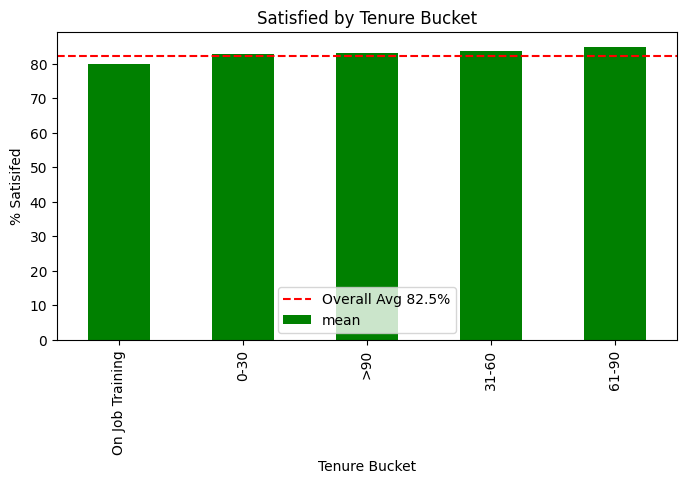

                      mean   size
Tenure Bucket                    
On Job Training  80.021941  25523
0-30             82.859162  11318
>90              83.277886  30660
31-60            83.746249  11665
61-90            85.031894   6741


In [367]:
df['Satisfied']=df['Satisfied'].astype(int)
avg=df['Satisfied'].mean()*100
g=df.groupby('Tenure Bucket')['Satisfied'].agg(['mean','size'])
g['mean']=g['mean']*100
g=g[g['size']>=200].sort_values('mean')
g['mean'].plot(kind='bar',color='green',figsize=(8,4))

plt.axhline(avg,color='red',linestyle='--',label=f"Overall Avg {avg:.1f}%")
plt.title("Satisfied by Tenure Bucket")
plt.ylabel('% Satisifed')
plt.legend()
plt.show()
print(g)

### Satisfied by Report Hour

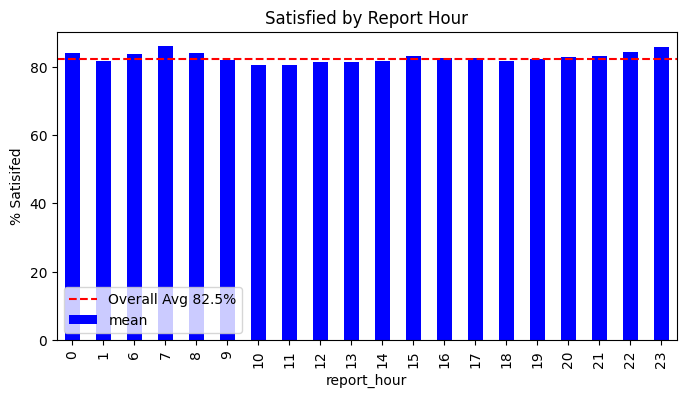

                  mean  size
report_hour                 
0            84.210526  1520
1            81.642512   414
6            83.728448   928
7            86.001830  2186
8            84.175761  3482
9            81.968680  4470
10           80.612245  5488
11           80.646800  5906
12           81.508018  5862
13           81.381215  5430
14           81.753995  5382
15           83.162612  4686
16           82.554406  5606
17           82.655644  5927
18           81.695502  5780
19           82.465986  5880
20           82.910382  5635
21           83.257356  4826
22           84.393064  3633
23           85.821518  2398


In [368]:
df['Satisfied']=df['Satisfied'].astype(int)
avg=df['Satisfied'].mean()*100
g=df.groupby('report_hour')['Satisfied'].agg(['mean','size'])
g['mean']=g['mean']*100
g=g[g['size']>=200].sort_values('mean').sort_index()
g['mean'].plot(kind='bar',color='blue',figsize=(8,4))

plt.axhline(avg,color='red',linestyle='--',label=f"Overall Avg {avg:.1f}%")
plt.title("Satisfied by Report Hour")
plt.ylabel('% Satisifed')
plt.legend()
plt.show()
print(g)

### Satisfied By Day Of Week

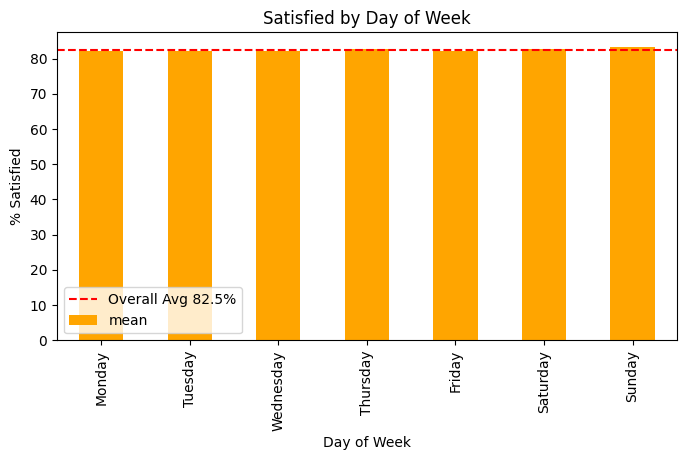

              dayofweek       mean   size
weekday_name                             
Monday                0  82.079150  12053
Tuesday               1  82.124352  14282
Wednesday             2  82.219614  13633
Thursday              3  82.692168  13803
Friday                4  82.118516  10564
Saturday              5  82.765757  10630
Sunday                6  83.330287  10942


In [369]:
import matplotlib.pyplot as plt

# Ensure type conversion and calculate global average
df["Satisfied"] = df["Satisfied"].astype(int)
avg = df["Satisfied"].mean() * 100

# Map day numbers to weekday names
g_map = {
    0: "Monday",
    1: "Tuesday",
    2: "Wednesday",
    3: "Thursday",
    4: "Friday",
    5: "Saturday",
    6: "Sunday",
}
df["weekday_name"] = df["dayofweek"].map(g_map)

#Group by BOTH 'dayofweek' and 'weekday_name' so we preserve the number for sorting
g = df.groupby(["dayofweek", "weekday_name"])["Satisfied"].agg(["mean", "size"])
g["mean"] = g["mean"] * 100

#  Filter for sample size
g = g[g["size"] >= 200]

#  Sort by the index level 'dayofweek' (chronological order)
g = g.sort_index(level="dayofweek")

#  Reset index or drop 'dayofweek' from the index so X-axis shows the strings nicely
g_plot = g.reset_index(level="dayofweek")

#  Plotting the Bar Chart
g_plot["mean"].plot(kind="bar", color="orange", figsize=(8, 4))

plt.axhline(avg, color="red", linestyle="--", label=f"Overall Avg {avg:.1f}%")
plt.title("Satisfied by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("% Satisfied")
plt.legend()
plt.show()

print(g_plot)


### Category Shift Heatmap

<Axes: xlabel='Agent Shift', ylabel='category'>

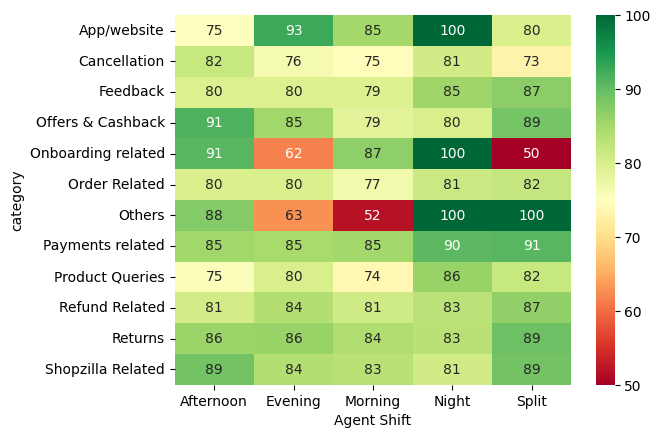

In [370]:
p = df.pivot_table(values='Satisfied', index='category',
                   columns='Agent Shift', aggfunc='mean')
sns.heatmap(p*100, annot=True, fmt='.0f', cmap='RdYlGn')

### Daily trend

                         mean  size
Issue_reported_at                  
2023-07-28         100.000000     2
2023-07-29          35.000000    20
2023-07-30          58.974359    39
2023-07-31          64.397906   191
2023-08-01          80.607685  2238
2023-08-02          80.481622  2367
2023-08-03          81.751527  2455
2023-08-04          81.589300  2542
2023-08-05          82.461538  2275
2023-08-06          81.631849  2537
                        mean  size
Issue_reported_at                 
2023-08-27         85.600000  3375
2023-08-28         85.969015  3421
2023-08-29         85.513720  3134
2023-08-30         85.708941  2673
2023-08-31         84.817720  2167


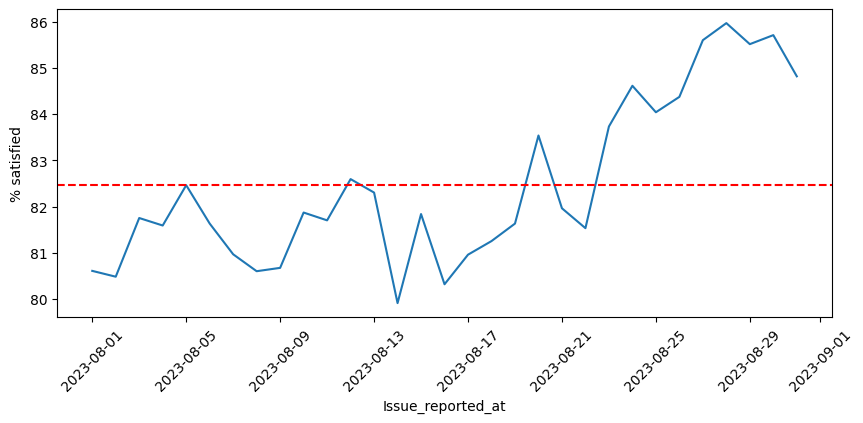

In [371]:
daily = df.groupby(df['Issue_reported_at'].dt.date)['Satisfied'].agg(['mean', 'size'])
daily['mean'] = daily['mean'] * 100
print(daily.head(10))
print(daily.tail(5))

daily = daily[daily['size'] >= 200]
daily['mean'].plot(figsize=(10, 4))
plt.axhline(avg, color='red', linestyle='--')
plt.ylabel("% satisfied")
plt.xticks(rotation=45)
plt.show()

1. Why did you pick the specific chart?

Satisfaction rose steadily through August, from ~80.6% on 1 Aug to ~85-86% in the last week. The first 4 days of data (28-31 Jul) had fewer than 200 tickets each, so they were excluded.

### Multivariate Analysis

### Chart- 9 Stacked Bar Chart (Complaints per Category per Shift)

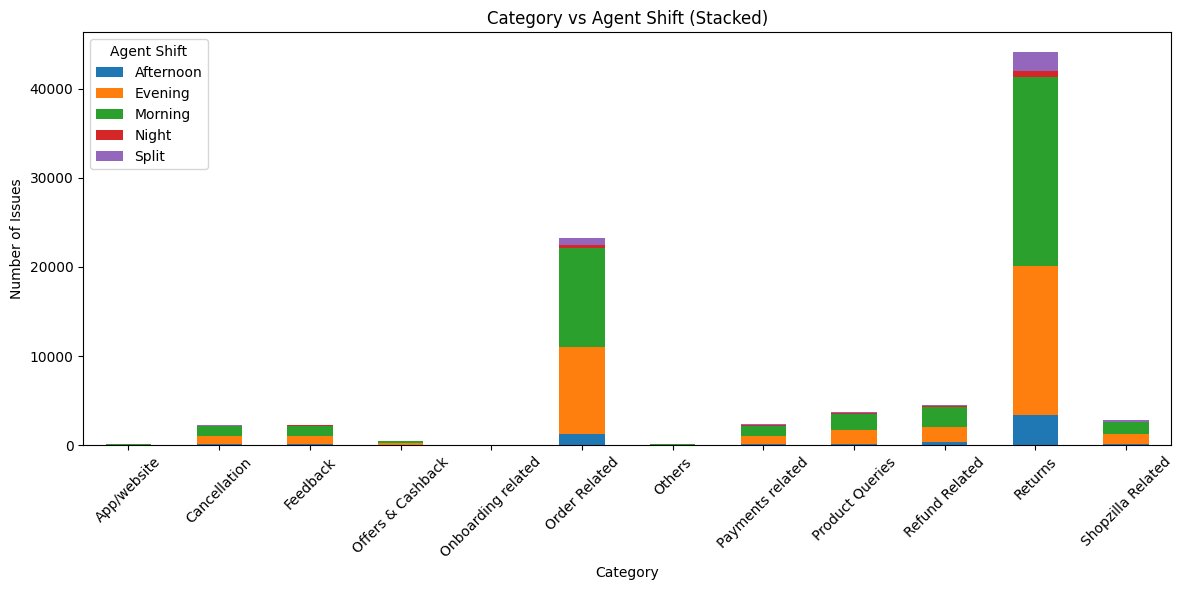

In [372]:
#create stacked bar for visualization
pd.crosstab(df['category'], df['Agent Shift']).plot(kind='bar', stacked=True, figsize=(12,6))
plt.title("Category vs Agent Shift (Stacked)")
plt.xlabel("Category")
plt.ylabel("Number of Issues")
plt.legend(title='Agent Shift')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [373]:
# This stacked bar chart shows how different 'Agent Shifts' handle issues across product 'categories'.
# Each bar shows the total issues per category, split by shift to see workload distribution.
# It helps identify which shifts handle more issues in each category and spot any imbalance.


##### 1. Why did you pick the specific chart?

We used a stacked bar chart to compare how different agent shifts handle various product categories. This visualization helps us analyze two variables simultaneously — the product category and the distribution of shifts. It provides a clear breakdown of how issues or orders are managed across shifts within each category.

##### 2. What is/are the insight(s) found from the chart?

Workload is spread across shifts for all categories.

### Bar Chart

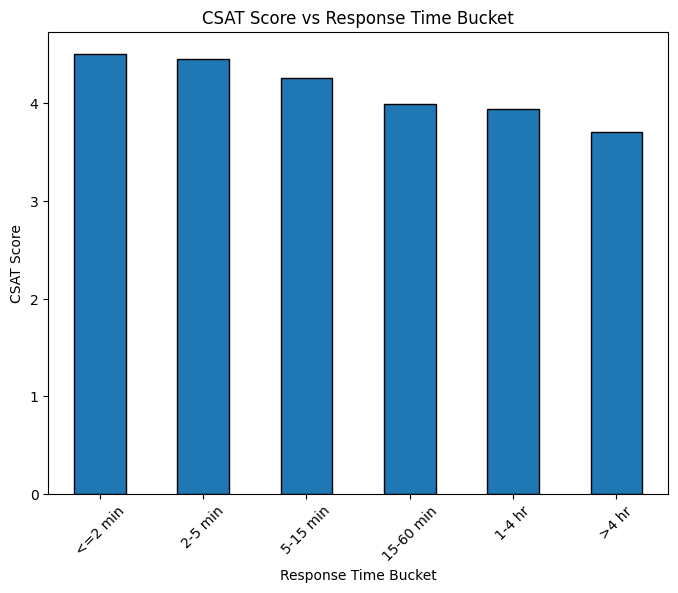

In [374]:
csat_data=df.groupby(df['response_bucket'])['CSAT Score'].mean()

plt.figure(figsize=(8,6))
csat_data.plot(kind='bar',edgecolor='black')

plt.xlabel("Response Time Bucket")
plt.ylabel("CSAT Score")
plt.title("CSAT Score vs Response Time Bucket")
plt.xticks(rotation=45)
plt.show()


1. Why did you pick the specific chart?

We use bar chart to see the satisfied score according to the response time. This visualization help us to analyze two variables simultaneously.

2. What is/are the insight(s) found from the chart?

People are most satisfied whenever they got the reply within 2 minutes. And reply takes more than 4 hour have less satisfy.

3. Will the gained insights help creating a positive business impact?

Yes! we found useful insights about customer satisfaction, it tells us people satisfy with fast reply/solutions, hours may leads to dissatifaction.

### Histogram - Response Time Bucket

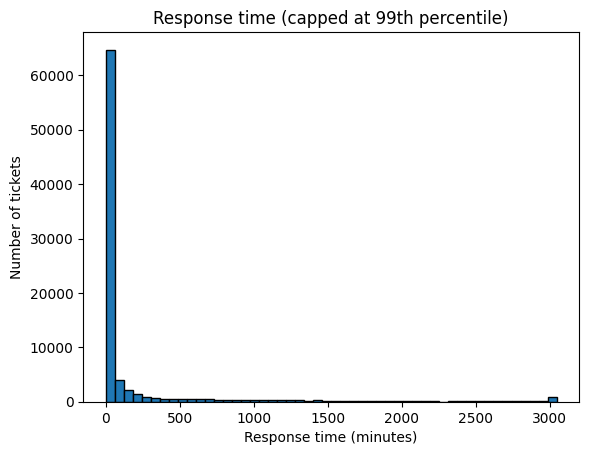

6.0 3047.220000000001


In [375]:
cap = df['response_time'].quantile(0.99)

df['response_time'].dropna().clip(upper=cap).hist(bins=50, edgecolor='black', grid=False)
plt.title("Response time (capped at 99th percentile)")
plt.xlabel("Response time (minutes)")
plt.ylabel("Number of tickets")
plt.show()

print(df['response_time'].median(), cap)

1. Why did you pick the specific chart?


We use histogram to understand the distribution of response time and reduce the visual impact of extreme values.This helps us to examine the response time of majority of tickets.

2. What isnights you found from above charts.


Response time distribution is highly right-skewed. The median response time is 6 minutes, whereas the 99th percentile is approximately 3047 minutes. This indicates that most tickets receive responses relatively quickly, but a small proportion experience extremely long delays. These delayed tickets may require further investigation.

## Insights

Insights 1: Response Time

- Satisfaction falls steadily as replies get slower: 89.5% satisfied when answered within 2 minutes, 83.0% at 5-15 min, 76.1% at 15-60 min and 68.1% after 4 hours (a 21-point gap).
Action: Set a response-time target (e.g. 15 minutes) and escalate tickets waiting more than 4 hours.

- Action: Set the response time ex: 15min.

In [376]:
print(df.groupby('response_bucket')['Satisfied'].mean()*100)

response_bucket
<=2 min      89.476345
2-5 min      87.981372
5-15 min     82.954054
15-60 min    76.082335
1-4 hr       74.320854
>4 hr        68.105066
Name: Satisfied, dtype: float64


Insight 2: Channel
- Email has 73% satisifed customer, Inbound 82% and Outcall has 83%,it shows email has the lowest satisfied customer.

- Action:Check the email response process.

Insight 3: Product Category

- Furniture (66%) , Mobile (66%), Home Appliences (68%) these are the product with less satisfaction.

- Action:Focus on these product related issues such as returns,installation etc.

Insight 4: Manager

- Customeer are more satisfied with John Smith (83%) and Emily Chen (86%) and customer with lowest satisfaction managers :William Kim (79.3%), Olivia Tan (79.4%).

- Action: Share best practices from Emily Chen’s team (86.1%) with the lowest-performing teams..

Insight 5: Weekday has no effect

- From Monday to Friday satisfaction is (82%) and Saturday,Sunday (83%) only (1%) increase so it shows satisfaction doesn't affected by week days.

##Limitations:

Findings are associations, not causes. No data on whether the issue was resolved. Data covers one month (Aug 2023).

## **5. Solution to Business Objective**

#### What do you suggest the client to achieve Business Objective ?
Explain Briefly.

We suggest the client to:

1. Set a response-time target (e.g. within 15 minutes), escalate tickets waiting more than 4 hours, and track the share of tickets answered within 15 minutes.

2. Review the Email support process (73.5% satisfied vs about 83% on other channels).

3. Investigate common issues (returns, installation) for Furniture, Mobile and Home Appliances (66-68% satisfied).

4. Share best practices from the top-performing team (Emily Chen, 86.1%) with the lowest-performing teams (79.3-79.4%).

5. Do not prioritise day-of-week changes, as satisfaction is almost the same on every day


# **Conclusion**

We analysed 85,907 Flipkart support tickets to find what affects customer satisfaction (82.5% satisfied overall). Response time showed the strongest association: 89.5% of customers answered within 2 minutes were satisfied, compared with 68.1% after 4 hours. The Email channel (73.5%) and Furniture, Mobile and Home Appliances (66-68%) were the weakest areas, while weekday had almost no effect (82.1% to 83.3%). These are associations, not proven causes, and the data has no information on whether issues were actually resolved.

### We have successfully completed EDA Capstone Project !!!